In [1]:
import numpy as np
import jax
import jax.numpy as jnp
import pypesto
from pypesto.result import OptimizerResult
import pypesto.profile as profile
from cmfa.functions import ordered_ilr_func, calculate_ci

import sys
sys.path.insert(0, "../scripts")
import toy_network
import tca_cycle

import pickle
from pathlib import Path

from functools import partial

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
from matplotlib.colors import to_rgba

from jax import config

config.update("jax_enable_x64", True)

import scipy.stats as stats
import optimistix

SEED = 1234
key = jax.random.key(seed=SEED)
key_toy, key = jax.random.split(key)
key_tca, key = jax.random.split(key)
RESULTS_DIR_TOY = Path("..") / "data" / "results" / "toy_example"
RESULTS_DIR_TCA = Path("..") / "data" / "results" / "tca_cycle"
PLOT_DIR = Path("..") / "figures"
# ── palette ───────────────────────────────────────────────────────────────────
CRIMSON = '#73102A'   # P point
INDIGO  = '#1C0B9C'   # Q point
OLIVE   = '#558C03'   # simplex face
TEAL    = '#038C7F'   # vertices
DIST_E  = "#DB7211"   # Euclidean distance (amber/gold)
DIST_A  = '#9C27B0'   # Aitchison distance (purple)

# Axis colors
A_COLOR = '#CC4400'   # Axis A (deep orange-red)
B_COLOR = '#007700'   # Axis B (forest green)
C_COLOR = '#0044BB'   # Axis C (medium blue)

TRAD  = "#DB7211" 
ILR =  '#038C7F'

combined = "#8CAA8D"
def fisher_interval(log_flux_est, flux_sd):
    mu = log_flux_est
    sigma = flux_sd
    x_start = (mu - 2.4 * sigma)
    x_end = (mu + 2.4 * sigma)
    x_axis = np.linspace(x_start, x_end, 500)
    
    # Calculate Log-Normal PDF
    y_raw = stats.norm.pdf(x_axis, mu, sigma)
    y_scaled = y_raw / np.max(y_raw)

    return np.exp(x_axis), y_scaled

In [2]:
# Toy network
true_mid_toy = np.load(RESULTS_DIR_TOY / "true_composition.npy")
true_flux_toy = np.load(RESULTS_DIR_TOY / "true_flux.npy")
simulated_mid_toy = jnp.load(RESULTS_DIR_TOY / "id_simulated_reference.npy")

with open(RESULTS_DIR_TOY / "estimated_fluxes_reference.pkl", "rb") as f:
    estimated_fluxes_toy = pickle.load(f)


sd_trad_toy = np.std(simulated_mid_toy, axis=0)
sd_ilr_toy = np.std(ordered_ilr_func(simulated_mid_toy), axis=0)

weights_trad_toy = 1/sd_trad_toy
weights_ilr_toy = 1/sd_ilr_toy

# 2. Optimization with Optimistix
# Note: Ensure loss_trad signature is: loss_trad(params, args)
init_guess_toy = jnp.array([100.0, 50.0])
solver = optimistix.BFGS(rtol=1e-8, atol=1e-8)

opt_result_trad_toy = optimistix.minimise(
    toy_network.loss_trad,
    y0=jnp.log(init_guess_toy),
    args=(true_mid_toy, weights_trad_toy),
    solver=solver,
    max_steps=10000,
    throw=False,
    has_aux=True,
)

opt_result_ilr_toy = optimistix.minimise(
    toy_network.loss_ilr,
    y0=jnp.log(init_guess_toy),
    args=(true_mid_toy, weights_ilr_toy),
    solver=solver,
    max_steps=10000,
    throw=False,
    has_aux=True,
)

est_trad_toy = estimated_fluxes_toy["trad"][:, [4, 5]]
est_ilr_toy = estimated_fluxes_toy["ilr"][:, [4, 5]]

inv_hessian_trad_toy = opt_result_trad_toy.state.f_info.hessian_inv.pytree
standard_errors_trad_toy = jnp.sqrt(jnp.diag(inv_hessian_trad_toy))

inv_hessian_ilr_toy = opt_result_ilr_toy.state.f_info.hessian_inv.pytree
standard_errors_ilr_toy = jnp.sqrt(jnp.diag(inv_hessian_ilr_toy))


In [3]:
# tca cycle
true_mid_tca = np.load(RESULTS_DIR_TCA / "true_composition.npy", allow_pickle=True).item()
true_flux_tca = np.load(RESULTS_DIR_TCA / "true_flux.npy", allow_pickle=True)
simulated_mid_tca = jnp.load(RESULTS_DIR_TCA / "id_simulated_reference.pkl", allow_pickle=True)

with open(RESULTS_DIR_TCA / "estimated_fluxes_reference.pkl", "rb") as f:
    estimated_fluxes_tca = pickle.load(f)

sd_trad_tca = jax.tree.map(lambda x: np.std(x, axis=0), simulated_mid_tca)
sd_ilr_tca = jax.tree.map(lambda x: np.std(ordered_ilr_func(x), axis=0), simulated_mid_tca)

weights_trad_tca = jax.tree.map(lambda s: 1/s, sd_trad_tca)
weights_ilr_tca = jax.tree.map(lambda s: 1/s, sd_ilr_tca)

init_guess_tca = np.array([0.2, 0.2, 0.2])
solver = optimistix.BFGS(rtol=1e-8, atol=1e-8)

opt_result_trad_tca = optimistix.minimise(
    tca_cycle.loss_trad,
    y0=jnp.log(init_guess_tca),
    args=(true_mid_tca, weights_trad_tca),
    solver=solver,
    max_steps=10000,
    throw=False,
    has_aux=True,
)

opt_result_ilr_tca = optimistix.minimise(
    tca_cycle.loss_ilr,
    y0=jnp.log(init_guess_tca),
    args=(true_mid_tca, weights_ilr_tca),
    solver=solver,
    max_steps=10000,
    throw=False,
    has_aux=True,
)

est_trad_tca = estimated_fluxes_tca["trad"]
est_ilr_tca = estimated_fluxes_tca["ilr"]

inv_hessian_trad_tca = opt_result_trad_tca.state.f_info.hessian_inv.pytree
standard_errors_trad_tca = jnp.sqrt(jnp.diag(inv_hessian_trad_tca))

inv_hessian_ilr_tca = opt_result_ilr_tca.state.f_info.hessian_inv.pytree
standard_errors_ilr_tca = jnp.sqrt(jnp.diag(inv_hessian_ilr_tca))

In [4]:
true_flux_toy

array([100., 110.,  50.,  20.,  20.,  80.])

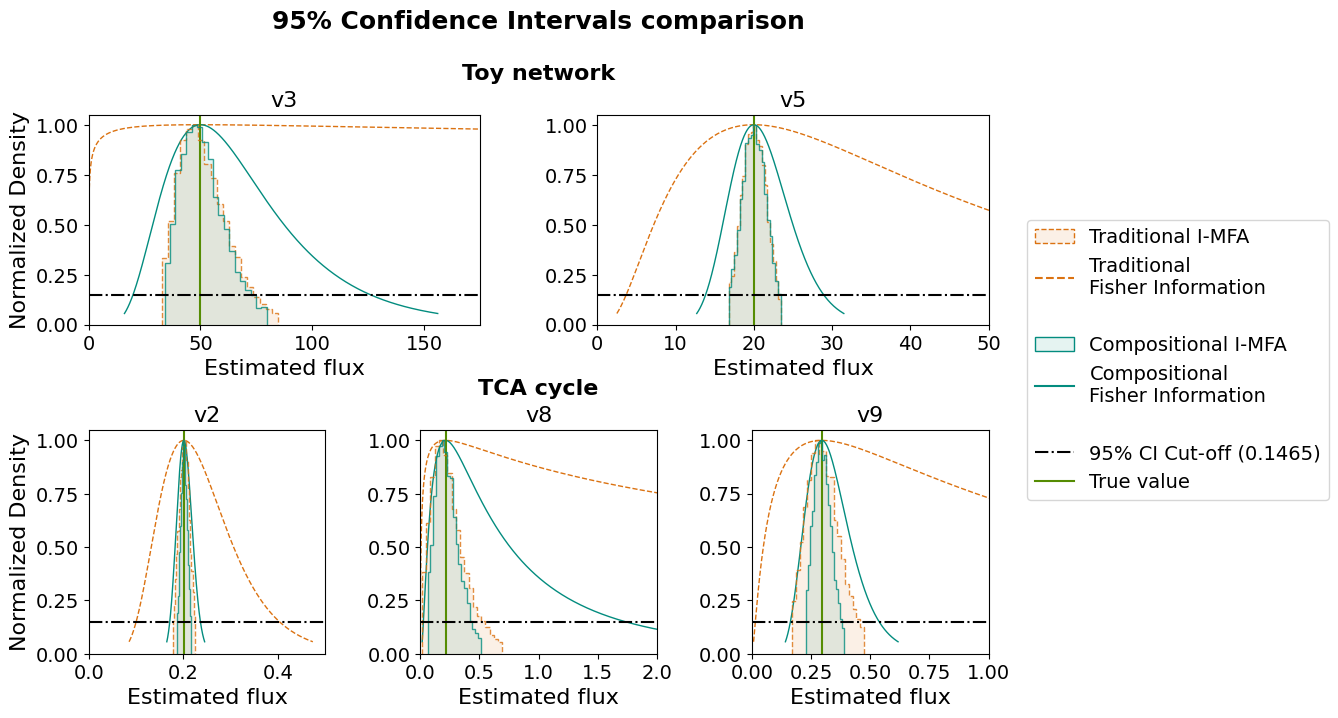

In [5]:
# --- Figure & Layout Setup ---
f = plt.figure(figsize=(10, 7))
 
# Top Row (Toy Network) — top lowered from 0.88 → 0.76 to leave room for the legend
gs1 = gridspec.GridSpec(1, 2, left=0.05, right=0.95, top=0.85, bottom=0.55, wspace=0.3)
ax1, ax2 = plt.subplot(gs1[0]), plt.subplot(gs1[1])
f.add_subplot(gs1[:, :], frameon=False).set_title("Toy network", fontsize=16, fontweight='bold', pad=25)
plt.axis('off')
 
# Bottom Row (TCA Cycle)
gs2 = gridspec.GridSpec(1, 3, left=0.05, right=0.95, top=0.40, bottom=0.08, wspace=0.4)
ax3, ax4, ax5 = plt.subplot(gs2[0]), plt.subplot(gs2[1]), plt.subplot(gs2[2])
f.add_subplot(gs2[:, :], frameon=False).set_title("TCA cycle", fontsize=16, fontweight='bold', pad=25)
plt.axis('off')
 
axes = [ax1, ax2, ax3, ax4, ax5]
 
# --- Unified Subplot Configuration ---
configs = [
    # Toy Network Subplots
    {"idx": 0, "true_value": true_flux_toy[2], "opt_t": opt_result_trad_toy, "opt_i": opt_result_ilr_toy, "se_t": standard_errors_trad_toy, "se_i": standard_errors_ilr_toy, "est_t": est_trad_toy[:, 0], "est_i": est_ilr_toy[:, 0], "title": "v3", "xlim": (0, 175)},
    {"idx": 1, "true_value": true_flux_toy[4], "opt_t": opt_result_trad_toy, "opt_i": opt_result_ilr_toy, "se_t": standard_errors_trad_toy, "se_i": standard_errors_ilr_toy, "est_t": est_trad_toy[:, 1], "est_i": est_ilr_toy[:, 1], "title": "v5", "xlim": (0, 50)},
    # TCA Cycle Subplots
    {"idx": 1, "true_value": true_flux_tca.item()["v2"], "opt_t": opt_result_trad_tca, "opt_i": opt_result_ilr_tca, "se_t": standard_errors_trad_tca, "se_i": standard_errors_ilr_tca, "est_t": est_trad_tca[:, 1], "est_i": est_ilr_tca[:, 1], "title": "v2", "xlim": (0, 0.5)},
    {"idx": 0, "true_value": true_flux_tca.item()["v8"], "opt_t": opt_result_trad_tca, "opt_i": opt_result_ilr_tca, "se_t": standard_errors_trad_tca, "se_i": standard_errors_ilr_tca, "est_t": est_trad_tca[:, 0], "est_i": est_ilr_tca[:, 0], "title": "v8", "xlim": (0, 2)},
    {"idx": 2, "true_value": true_flux_tca.item()["v9"], "opt_t": opt_result_trad_tca, "opt_i": opt_result_ilr_tca, "se_t": standard_errors_trad_tca, "se_i": standard_errors_ilr_tca, "est_t": est_trad_tca[:, 2], "est_i": est_ilr_tca[:, 2], "title": "v9", "xlim": (0, 1)},
]
 
# --- Execution Loop ---
for ax, cfg in zip(axes, configs):
    idx = cfg["idx"]
    et, ei = cfg["est_t"].flatten(), cfg["est_i"].flatten()

    # 2. Fisher Information Intervals
    ax.plot(*fisher_interval(cfg["opt_t"].value[idx], cfg["se_t"][idx]), color=TRAD, lw=1, linestyle = "--")
    ax.plot(*fisher_interval(cfg["opt_i"].value[idx], cfg["se_i"][idx]), color=ILR, lw=1)
    ax.axvline(cfg["true_value"], color= OLIVE)
    # 3. Peak-Normalized Histograms
    bins_et = np.linspace(np.quantile(et, 0.025), np.quantile(et, 0.975), 20)
    bins_ei = np.linspace(np.quantile(ei, 0.025), np.quantile(ei, 0.975), 20)
    ax.hist(et, bins=bins_et, weights=np.ones_like(et) / np.max(np.histogram(et, bins=bins_et)[0]), histtype='step', color=TRAD, alpha=0.8, linestyle="--")
    ax.hist(ei, bins=bins_ei, weights=np.ones_like(ei) / np.max(np.histogram(ei, bins=bins_ei)[0]), histtype='step', color=ILR, alpha=0.8, linestyle="-")
    ax.hist(et, bins=bins_et, weights=np.ones_like(et) / np.max(np.histogram(et, bins=bins_et)[0]), color=TRAD, alpha=0.1)
    ax.hist(ei, bins=bins_ei, weights=np.ones_like(ei) / np.max(np.histogram(ei, bins=bins_ei)[0]), color=ILR, alpha=0.1)
 
    # 4. Global Subplot Formatting
    ax.axhline(0.1465, color="black", linestyle="-.")
    ax.set_title(cfg["title"], fontsize=16)
    ax.set_xlim(cfg["xlim"])
    ax.set_xlabel("Estimated flux", fontsize=16)
    ax.tick_params(axis='both', labelsize=14)
    # Y-axis label only on leftmost subplot per row (ax1 for Toy Network, ax3 for TCA Cycle)
    if ax in [ax1, ax3]:
        ax.set_ylabel("Normalized Density", fontsize=16)
 
# --- Legend & Figure Output ---
# 1. Define the elements individually for easy sorting
trad_mfa = mpatches.Patch(edgecolor=TRAD, linestyle="--", facecolor=to_rgba(TRAD, alpha=0.1))
trad_fish = Line2D([0], [0], color=TRAD, linestyle="--", markersize=6)
 
comp_mfa  = mpatches.Patch(edgecolor=ILR, linestyle="-", facecolor=to_rgba(ILR, alpha=0.1))
comp_fish = Line2D([0], [0], color=ILR, linestyle="-", markersize=6)

true_val = Line2D([0], [0], color=OLIVE, linestyle="-", markersize=6)

cutoff    = Line2D([0], [0], color="black", linestyle="-.", markersize=6)
dummy     = Line2D([], [], linestyle="")  # Invisible spacer to hold the grid shape

 
# 2. Arrange them explicitly row-by-row so they line up column-by-column
# Row 1: MFAST / MFAC / Cutoff
# Row 2: Profile T / Profile C / Blank Spacer
# Row 3: Fisher T / Fisher C
custom_markers = [
    trad_mfa, trad_fish, dummy,
    comp_mfa, comp_fish, dummy,
    cutoff, true_val
]

custom_labels = [
    "Traditional I-MFA", "Traditional\nFisher Information", "",             
    "Compositional I-MFA", "Compositional\nFisher Information", "",
     "95% CI Cut-off (0.1465)", "True value",    
]

# 3. Render the centered 3-column legend
f.legend(
    custom_markers,
    custom_labels,
    fontsize=14,
    loc="right",
    bbox_to_anchor=(1.3, 0.5),
    ncol=1,
)
 
# Render main title slightly higher to clear the 3-row legend blocks
f.suptitle("95% Confidence Intervals comparison", fontsize=18, fontweight='bold', y=1)
 
plt.savefig(PLOT_DIR / 'CI.svg', dpi=600, bbox_inches='tight', pad_inches=0.12)
plt.show()
 


In [6]:
# est_trad_toy[:, 0], "est_i": est_ilr_toy[:, 0]
mc_toy_trad = np.array([[np.quantile(est_trad_toy[:, 0], 0.025), np.quantile(est_trad_toy[:, 0], 0.975)], 
                        [np.quantile(est_trad_toy[:, 1], 0.025), np.quantile(est_trad_toy[:, 1], 0.975)]])

mc_toy_ilr = np.array([[np.quantile(est_ilr_toy[:, 0], 0.025), np.quantile(est_ilr_toy[:, 0], 0.975)], 
                        [np.quantile(est_ilr_toy[:, 1], 0.025), np.quantile(est_ilr_toy[:, 1], 0.975)]])

mc_tca_trad = np.array([[np.quantile(est_trad_tca[:, 0], 0.025), np.quantile(est_trad_tca[:, 0], 0.975)], 
                        [np.quantile(est_trad_tca[:, 1], 0.025), np.quantile(est_trad_tca[:, 1], 0.975)],
                        [np.quantile(est_trad_tca[:, 2], 0.025), np.quantile(est_trad_tca[:, 2], 0.975)]])

mc_tca_ilr = np.array([[np.quantile(est_ilr_tca[:, 0], 0.025), np.quantile(est_ilr_tca[:, 0], 0.975)], 
                        [np.quantile(est_ilr_tca[:, 1], 0.025), np.quantile(est_ilr_tca[:, 1], 0.975)],
                        [np.quantile(est_ilr_tca[:, 2], 0.025), np.quantile(est_ilr_tca[:, 2], 0.975)]])

In [7]:
print(mc_toy_trad)
print(mc_toy_ilr)

[[32.61936979 84.62397076]
 [16.77060508 23.48504079]]
[[33.98657877 79.70724944]
 [16.77721228 23.42448322]]


In [8]:
print(mc_tca_trad)
print(mc_tca_ilr)

[[0.01490581 0.69355434]
 [0.17754027 0.22430539]
 [0.16961864 0.4737642 ]]
[[0.06284598 0.51100041]
 [0.18705802 0.21619725]
 [0.22832877 0.39005526]]


In [9]:
np.median(est_trad_tca[:, 2])

np.float64(0.2957913867361436)

In [10]:
np.median(est_ilr_tca[:, 2])

np.float64(0.295839870919572)

In [11]:
def get_sigma_v(N, inv_hessian, ix_input_flux):
    n_nofixed = jnp.delete(N, ix_input_flux, axis=1)
    # jax.debug.breakpoint()
    return n_nofixed @ inv_hessian @ n_nofixed.T

In [12]:
m_toy = jnp.array([[-1, -1, 2], [0, 0, -1], [-1, 0, 1]])
n_toy = jnp.vstack([-m_toy, jnp.eye(3)])
ix_input_flux_toy = np.array([0])

sigma_v_trad = get_sigma_v(n_toy, inv_hessian_trad_toy, ix_input_flux_toy)
v3_trad, v5_trad = jnp.exp(opt_result_trad_toy.value)

v_free_trad = jnp.array([100, v3_trad, v5_trad])
# The fluxes calcualted from M and the free fluxes
v_full_trad = n_toy @ v_free_trad

flux_ci_toy_trad = calculate_ci(sigma_v_trad, jnp.log(v_full_trad))
print(flux_ci_toy_trad)

[[2.02222901e-02 5.98349641e+05]
 [3.65250402e+00 1.09513911e+02]
 [1.46100161e+01 4.38055644e+02]
 [1.00000000e+02 1.00000000e+02]
 [4.91816951e-04 5.08319203e+06]
 [3.65250402e+00 1.09513911e+02]]


In [13]:
sigma_v_ilr = get_sigma_v(n_toy, inv_hessian_ilr_toy, ix_input_flux_toy)
v3_ilr, v5_ilr = jnp.exp(opt_result_ilr_toy.value)

v_free_ilr = jnp.array([100, v3_ilr, v5_ilr])
# The fluxes calcualted from M and the free fluxes
v_full_ilr = n_toy @ v_free_ilr

flux_ci_toy_ilr = calculate_ci(sigma_v_ilr, jnp.log(v_full_ilr))
print(flux_ci_toy_ilr)

[[ 21.23913665 569.7030062 ]
 [ 13.8036716   28.97779747]
 [ 55.2146864  115.91118988]
 [100.         100.        ]
 [ 19.73202985 126.69755819]
 [ 13.8036716   28.97779747]]


In [14]:
V_FREE = {"v8": 0.215, "v1": 1, "v19": 0.05, "v20": 0.03, "v16": 0.07, "v17": 0.23, "v18": 0.12, "v2": 0.201, "v9": 0.296}
KNOWN_KEYS = ["v1", "v16", "v17", "v18", "v19", "v20"]
KNOWN_FLUXES = {k: V_FREE[k] for k in KNOWN_KEYS}
FREE_KEYS = ["v8", "v2", "v9"]

flux_from_free = partial(
    tca_cycle.flux_vector,
    fixed=KNOWN_FLUXES,
)
n_tca = tca_cycle.get_N()
ix_input_flux_tca = np.array([1,2,3,4,5,6])

In [15]:
flux_est_trad = flux_from_free(jnp.exp(opt_result_trad_tca.value))
sigma_v_tca_trad = get_sigma_v(n_tca, inv_hessian_trad_tca, ix_input_flux_tca)
flux_est_jax = jnp.array([flux_est_trad[k] for k in flux_est_trad.keys()])
flux_ci_tca_trad = calculate_ci(sigma_v_tca_trad, jnp.log(flux_est_jax))
print(flux_ci_tca_trad)

[[6.38448227e-04 7.24021120e+01]
 [1.00000000e+00 1.00000000e+00]
 [5.00000000e-02 5.00000000e-02]
 [3.00000000e-02 3.00000000e-02]
 [7.00000000e-02 7.00000000e-02]
 [2.30000000e-01 2.30000000e-01]
 [1.20000000e-01 1.20000000e-01]
 [9.98741958e-02 4.04518902e-01]
 [1.46236945e-02 5.99137245e+00]
 [3.08566545e-01 1.24978228e+00]
 [3.08566545e-01 1.24978228e+00]
 [3.08566545e-01 1.24978228e+00]
 [1.46162574e-01 2.39776839e+00]
 [1.48810136e-01 9.88755899e+00]
 [1.47078418e-01 5.95709428e-01]
 [9.19852496e-02 2.47548494e+01]
 [5.25515667e-02 5.72813559e+01]
 [2.32961353e-04 1.32746143e+05]
 [3.59317756e-02 6.27926107e+00]
 [1.09465053e-03 5.94937819e+02]]


In [16]:
flux_est_ilr = flux_from_free(jnp.exp(opt_result_ilr_tca.value))
sigma_v_tca_ilr = get_sigma_v(n_tca, inv_hessian_ilr_tca, ix_input_flux_tca)
flux_est_jax_ilr = jnp.array([flux_est_ilr[k] for k in flux_est_ilr.keys()])
flux_ci_tca_ilr = calculate_ci(sigma_v_tca_ilr, jnp.log(flux_est_jax_ilr))
print(flux_ci_tca_ilr)

[[2.63360694e-02 1.75519738e+00]
 [1.00000000e+00 1.00000000e+00]
 [5.00000000e-02 5.00000000e-02]
 [3.00000000e-02 3.00000000e-02]
 [7.00000000e-02 7.00000000e-02]
 [2.30000000e-01 2.30000000e-01]
 [1.20000000e-01 1.20000000e-01]
 [1.71069624e-01 2.36167001e-01]
 [1.62382191e-01 5.39566559e-01]
 [5.28528539e-01 7.29650287e-01]
 [5.28528539e-01 7.29650287e-01]
 [5.28528539e-01 7.29650287e-01]
 [4.28820355e-01 8.17274637e-01]
 [7.47810104e-01 1.96757037e+00]
 [2.51923426e-01 3.47788220e-01]
 [7.91765566e-01 2.87595356e+00]
 [7.74789439e-01 3.88521687e+00]
 [3.91871960e-01 7.89153707e+01]
 [2.65759843e-01 8.48980785e-01]
 [8.44664403e-02 7.71015089e+00]]


In [17]:
# reduction
for i in np.array([4, 5]):
    print(((flux_ci_toy_trad[i,1]-flux_ci_toy_trad[i,0]) - (flux_ci_toy_ilr[i,1]-flux_ci_toy_ilr[i,0]))/(flux_ci_toy_trad[i,1]-flux_ci_toy_trad[i,0]))

for i in np.array([0, 7, 8]):
    print(((flux_ci_tca_trad[i,1]-flux_ci_tca_trad[i,0]) - (flux_ci_tca_ilr[i,1]-flux_ci_tca_ilr[i,0]))/(flux_ci_tca_trad[i,1]-flux_ci_tca_trad[i,0]))

0.9999789570160221
0.856660455317294
0.976121186105874
0.7863170568868507
0.9368913795807222


In [18]:
np.mean(np.array([0.9999789570160221,
                0.856660455317294,
                0.9761211861278558,
                0.7863170530498749,
                0.9368913794559693]))

np.float64(0.9111938061934032)

## Profile likelihood

In [19]:
with open(RESULTS_DIR_TOY / "profile_likelihood.pkl", "rb") as f:
    profile_toy = pickle.load(f)
with open(RESULTS_DIR_TCA / "profile_likelihood.pkl", "rb") as f:
    profile_tca = pickle.load(f)

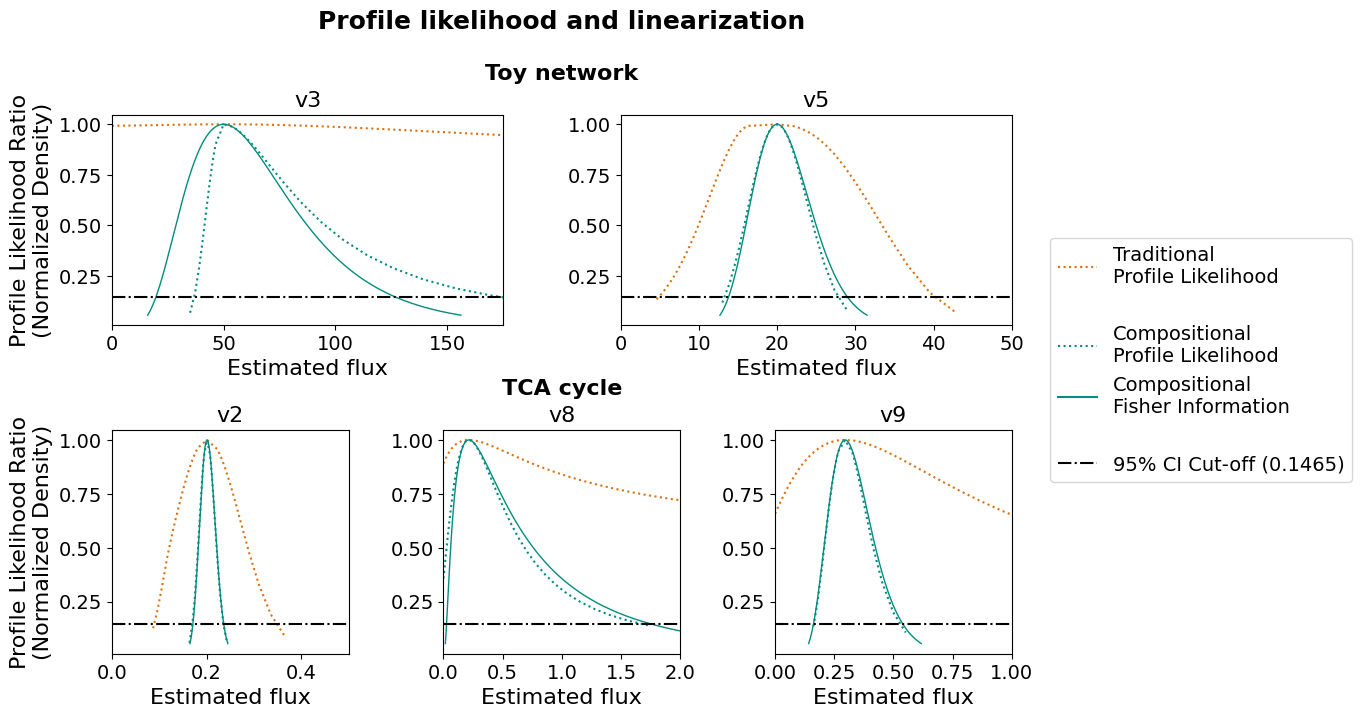

In [20]:
# --- Figure & Layout Setup ---
f = plt.figure(figsize=(10, 7))
 
# Top Row (Toy Network) — top lowered from 0.88 → 0.76 to leave room for the legend
gs1 = gridspec.GridSpec(1, 2, left=0.05, right=0.95, top=0.85, bottom=0.55, wspace=0.3)
ax1, ax2 = plt.subplot(gs1[0]), plt.subplot(gs1[1])
f.add_subplot(gs1[:, :], frameon=False).set_title("Toy network", fontsize=16, fontweight='bold', pad=25)
plt.axis('off')
 
# Bottom Row (TCA Cycle)
gs2 = gridspec.GridSpec(1, 3, left=0.05, right=0.95, top=0.40, bottom=0.08, wspace=0.4)
ax3, ax4, ax5 = plt.subplot(gs2[0]), plt.subplot(gs2[1]), plt.subplot(gs2[2])
f.add_subplot(gs2[:, :], frameon=False).set_title("TCA cycle", fontsize=16, fontweight='bold', pad=25)
plt.axis('off')
 
axes = [ax1, ax2, ax3, ax4, ax5]

configs = [
    # Toy Network Subplots
    {"res_t": profile_toy["trad"]["v3"], "res_i": profile_toy["ilr"]["v3"], "idx": 0, "opt_t": opt_result_trad_toy, "opt_i": opt_result_ilr_toy, "se_t": standard_errors_trad_toy, "se_i": standard_errors_ilr_toy, "est_t": est_trad_toy[:, 0], "est_i": est_ilr_toy[:, 0], "title": "v3", "xlim": (0, 175)},
    {"res_t": profile_toy["trad"]["v5"], "res_i": profile_toy["ilr"]["v5"], "idx": 1, "opt_t": opt_result_trad_toy, "opt_i": opt_result_ilr_toy, "se_t": standard_errors_trad_toy, "se_i": standard_errors_ilr_toy, "est_t": est_trad_toy[:, 1], "est_i": est_ilr_toy[:, 1], "title": "v5", "xlim": (0, 50)},
    # TCA Cycle Subplots
    {"res_t": profile_tca["trad"]["v2"], "res_i": profile_tca["ilr"]["v2"], "idx": 1, "opt_t": opt_result_trad_tca, "opt_i": opt_result_ilr_tca, "se_t": standard_errors_trad_tca, "se_i": standard_errors_ilr_tca, "est_t": est_trad_tca[:, 1], "est_i": est_ilr_tca[:, 1], "title": "v2", "xlim": (0, 0.5)},
    {"res_t": profile_tca["trad"]["v8"], "res_i": profile_tca["ilr"]["v8"], "idx": 0, "opt_t": opt_result_trad_tca, "opt_i": opt_result_ilr_tca, "se_t": standard_errors_trad_tca, "se_i": standard_errors_ilr_tca, "est_t": est_trad_tca[:, 0], "est_i": est_ilr_tca[:, 0], "title": "v8", "xlim": (0, 2)},
    {"res_t": profile_tca["trad"]["v9"], "res_i": profile_tca["ilr"]["v9"], "idx": 2, "opt_t": opt_result_trad_tca, "opt_i": opt_result_ilr_tca, "se_t": standard_errors_trad_tca, "se_i": standard_errors_ilr_tca, "est_t": est_trad_tca[:, 2], "est_i": est_ilr_tca[:, 2], "title": "v9", "xlim": (0, 1)},
]

 
# --- Execution Loop ---
for ax, cfg in zip(axes, configs):
    idx, rt, ri = cfg["idx"], cfg["res_t"], cfg["res_i"]
    et, ei = cfg["est_t"].flatten(), cfg["est_i"].flatten()
 
    # 1. Profile Likelihood Paths
    ax.plot(rt[0,:], rt[1,:], color=TRAD, linestyle=":")
    ax.plot(ri[0,:], ri[1,:], color=ILR, linestyle=":")
 
    # 2. Fisher Information Intervals
    # ax.plot(*fisher_interval(cfg["opt_t"].value[idx], cfg["se_t"][idx]), color=TRAD, lw=1)
    ax.plot(*fisher_interval(cfg["opt_i"].value[idx], cfg["se_i"][idx]), color=ILR, lw=1)

    # 4. Global Subplot Formatting
    ax.axhline(0.1465, color="black", linestyle="-.")
    ax.set_title(cfg["title"], fontsize=16)
    ax.set_xlim(cfg["xlim"])
    ax.set_xlabel("Estimated flux", fontsize=16)
    ax.tick_params(axis='both', labelsize=14)
    # Y-axis label only on leftmost subplot per row (ax1 for Toy Network, ax3 for TCA Cycle)
    if ax in [ax1, ax3]:
        ax.set_ylabel("Profile Likelihood Ratio\n(Normalized Density)", fontsize=16)
 
# --- Legend & Figure Output ---
# 1. Define the elements individually for easy sorting
trad_prof = Line2D([0], [0], color=TRAD, linestyle=":", markersize=6)
trad_fish = Line2D([0], [0], color=TRAD, linestyle="-", markersize=6)

comp_prof = Line2D([0], [0], color=ILR, linestyle=":", markersize=6)
comp_fish = Line2D([0], [0], color=ILR, linestyle="-", markersize=6)
 
cutoff    = Line2D([0], [0], color="black", linestyle="-.", markersize=6)
dummy     = Line2D([], [], linestyle="")  # Invisible spacer to hold the grid shape
 
# 2. Arrange them explicitly row-by-row so they line up column-by-column
# Row 1: MFAST / MFAC / Cutoff
# Row 2: Profile T / Profile C / Blank Spacer
# Row 3: Fisher T / Fisher C
custom_markers = [
    trad_prof, dummy,
    comp_prof, comp_fish, dummy,
    cutoff,
]

custom_labels = [
    "Traditional\nProfile Likelihood", "",             
    "Compositional\nProfile Likelihood", "Compositional\nFisher Information", "",
     "95% CI Cut-off (0.1465)",    
]
 
# 3. Render the centered 3-column legend
f.legend(
    custom_markers,
    custom_labels,
    fontsize=14,
    loc="right",
    bbox_to_anchor=(1.3, 0.5),
    ncol=1,
)
 
# Render main title slightly higher to clear the 3-row legend blocks
f.suptitle("Profile likelihood and linearization", fontsize=18, fontweight='bold', y=1)
plt.savefig(PLOT_DIR / 'profile_likelihood.svg', dpi=600, bbox_inches='tight', pad_inches=0.12)
plt.show()

In [21]:
profile_cis_toy_trad = profile_toy["trad"]["ci"]
profile_cis_toy_ilr = profile_toy["ilr"]["ci"]
print(profile_cis_toy_trad)
print(profile_cis_toy_ilr)

[[3.35462628e-04 8.88611052e+06]
 [4.88135758e+00 4.02343741e+01]]
[[ 36.76985492 173.6998743 ]
 [ 13.2793291   27.87954739]]


In [22]:
profile_cis_tca_trad = profile_tca["trad"]["ci"]
profile_cis_tca_ilr = profile_tca["ilr"]["ci"]
print(profile_cis_tca_trad)
print(profile_cis_tca_ilr)

[[3.35462628e-04 4.03428793e+02]
 [8.92910621e-02 3.48495924e-01]
 [3.35462628e-04 1.08925408e+01]]
[[3.35462628e-04 1.68135771e+00]
 [1.69913487e-01 2.35588410e-01]
 [1.64412258e-01 5.29698042e-01]]


In [23]:
np.exp(-6)

np.float64(0.0024787521766663585)

In [26]:
np.exp(+16)

np.float64(8886110.520507872)